# Tugas Hands-On 3: Pandas Lanjutan
**Kasus 03: E-Commerce Transactions**, klasifikasi biner dengan target `status_retur` (Diretur/Tidak Diretur), ditambah segmentasi pelanggan (RFM + KMeans).

Dataset diunduh otomatis dari Google Drive (Colab meminta izin akun Google satu kali karena file bersifat privat). Jalankan dengan *Runtime → Run all*.

## 0. Setup
Import library, atur `SEED = 2026` agar hasil **dapat direproduksi**, dan buat struktur folder pengumpulan `tugas-hands-on-3/` (`data/`, `output/`). Semua file keluaran ditulis ke folder ini.

In [1]:
import io, os, re, glob, tempfile, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, silhouette_score

warnings.filterwarnings('ignore')
SEED = 2026
np.random.seed(SEED)

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

BASE = 'tugas-hands-on-3'                      # folder pengumpulan
os.makedirs(f'{BASE}/data', exist_ok=True)
os.makedirs(f'{BASE}/output', exist_ok=True)
print('pandas', pd.__version__)

pandas 3.0.6


## 1. Data
Sel di bawah memuat dataset dengan urutan prioritas: CSV/Excel di folder kerja → **unduh dari `LINK_DATASET`** (tanpa login jika tautan publik, atau dengan akun Google Anda di Colab) → cari di Google Drive (di-mount otomatis) → unggah manual sebagai cadangan terakhir.
Data mentah **tidak pernah disunting manual**; semua perubahan dilakukan lewat kode pada salinan (`df`), sedangkan `df_mentah` dipertahankan apa adanya sebagai pembanding "sebelum".

In [2]:
NAMA_FILE    = 'case3_ecommerce_transactions'
PATH_CSV     = f'{BASE}/data/{NAMA_FILE}.csv'
LINK_DATASET = 'https://drive.google.com/file/d/1-eA56iLjUA7HD-FNgDIJIm87kMO_evY2/view?usp=sharing'   # tautan file di Google Drive; None = lewati
DRIVE_ROOT   = '/content/drive/MyDrive'   # lokasi "My Drive" setelah Drive di-mount di Colab

def baca(path):
    return pd.read_csv(path) if path.lower().endswith('.csv') else pd.read_excel(path)

def ambil_id(link):
    m = re.search(r'/d/([A-Za-z0-9_-]+)', link) or re.search(r'[?&]id=([A-Za-z0-9_-]+)', link)
    return m.group(1) if m else None

def simpan_unduhan(data, dasar):
    """Simpan byte hasil unduhan; kembalikan path, atau None jika isinya halaman HTML (login/error)."""
    awal = data.lstrip()[:200].lower()
    if awal.startswith(b'<!doctype') or b'<html' in awal:
        return None
    path = dasar + ('.xlsx' if data[:2] == b'PK' else '.csv')      # xlsx = file zip ("PK")
    with open(path, 'wb') as f:
        f.write(data)
    return path

def unduh_dari_link(link, dasar):
    """Unduh dataset dari tautan Google Drive/Sheets. Kembalikan path file, atau None bila gagal."""
    fid = ambil_id(link)
    if not fid:
        print('Tautan tidak dikenali (ID file tidak ditemukan).')
        return None
    # 1) tanpa login: berhasil bila tautan dibagikan "Siapa saja yang memiliki link"
    for url in [f'https://docs.google.com/spreadsheets/d/{fid}/export?format=xlsx',   # Google Sheets asli
                f'https://drive.google.com/uc?export=download&id={fid}']:              # file Excel/CSV yang diunggah ke Drive
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=60) as r:
                path = simpan_unduhan(r.read(), dasar)
            if path:
                return path
        except Exception:
            pass
    # 2) dengan akun Google Anda (khusus Colab): untuk file privat yang bisa Anda buka
    try:
        from google.colab import auth
        auth.authenticate_user()                                   # muncul permintaan izin satu kali
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        svc  = build('drive', 'v3')
        meta = svc.files().get(fileId=fid, fields='name,mimeType', supportsAllDrives=True).execute()
        if meta['mimeType'] == 'application/vnd.google-apps.spreadsheet':
            minta = svc.files().export_media(fileId=fid, mimeType='application/vnd.openxmlformats-officedocument.spreadsheetml.sheet')
        else:
            minta = svc.files().get_media(fileId=fid, supportsAllDrives=True)
        buf, dl, selesai = io.BytesIO(), None, False
        dl = MediaIoBaseDownload(buf, minta)
        while not selesai:
            _, selesai = dl.next_chunk()
        return simpan_unduhan(buf.getvalue(), dasar)
    except ImportError:
        print('Tautan privat tidak bisa diunduh tanpa login, dan login Google hanya tersedia di Colab.')
    except Exception as e:
        print(f'Unduh dengan akun Google gagal: {type(e).__name__}: {e}')
        print('Pastikan Anda login dengan akun Google yang punya akses ke file tersebut.')
    return None

def cari_di_drive():
    """Mount Google Drive (khusus Colab), lalu cari file dataset di My Drive."""
    try:
        from google.colab import drive
        drive.mount('/content/drive')            # muncul permintaan izin satu kali
    except ImportError:
        pass                                      # bukan di Colab
    if not os.path.isdir(DRIVE_ROOT):
        return None
    for folder in ['', f'/{BASE}/data', f'/{BASE}', '/Colab Notebooks', '/data']:   # lokasi umum dulu
        for ext in ['xlsx', 'csv']:
            p = f'{DRIVE_ROOT}{folder}/{NAMA_FILE}.{ext}'
            if os.path.exists(p):
                return p
    ketemu = sorted(glob.glob(f'{DRIVE_ROOT}/**/{NAMA_FILE}*.xls*', recursive=True) +
                    glob.glob(f'{DRIVE_ROOT}/**/{NAMA_FILE}*.csv', recursive=True))   # cari ke semua subfolder
    return ketemu[0] if ketemu else None

def muat_data():
    for p in [PATH_CSV, f'{NAMA_FILE}.csv', f'{BASE}/data/{NAMA_FILE}.xlsx', f'{NAMA_FILE}.xlsx']:
        if os.path.exists(p):
            print('Memuat dari folder kerja:', p)
            return baca(p)
    if LINK_DATASET:
        p = unduh_dari_link(LINK_DATASET, os.path.join(tempfile.gettempdir(), NAMA_FILE))   # file sementara, tidak masuk folder pengumpulan
        if p:
            print('Memuat dari tautan Google Drive/Sheets:', p)
            return baca(p)
        print('Tautan belum bisa diakses; mencoba mencari file di Google Drive Anda...')
    p = cari_di_drive()
    if p:
        print('Memuat dari Google Drive:', p)
        return baca(p)
    try:                                          # cadangan terakhir: unggah manual (Colab)
        from google.colab import files
        print(f'{NAMA_FILE} tidak ditemukan. Silakan unggah file dataset...')
        return baca(list(files.upload().keys())[0])
    except ImportError:
        raise FileNotFoundError(
            'Dataset tidak ditemukan. Pastikan LINK_DATASET dibagikan ("Siapa saja yang memiliki link") atau dibuka '
            f'dengan akun Google yang sama di Colab, atau letakkan {NAMA_FILE}.csv/.xlsx di folder kerja.')

df_mentah = muat_data()
KOLOM_WAJIB = ['transaction_id', 'user_id', 'product_id', 'kategori_produk', 'nama_produk', 'harga_idr', 'kuantitas',
               'diskon_pct', 'rating_pembeli', 'sentimen_ulasan', 'tanggal_pembelian', 'metode_pembayaran',
               'kota_pembeli', 'status_retur']
hilang = set(KOLOM_WAJIB) - set(df_mentah.columns)
assert not hilang, f'Kolom tidak ditemukan: {sorted(hilang)}. Apakah ini file dataset kasus 03 yang benar?'

kosong_asli = df_mentah['tanggal_pembelian'].isna().sum()
df_mentah['tanggal_pembelian'] = pd.to_datetime(df_mentah['tanggal_pembelian'], errors='coerce')
gagal = df_mentah['tanggal_pembelian'].isna().sum() - kosong_asli
assert gagal == 0, f'{gagal} tanggal gagal dibaca; periksa format tanggal pada file.'

# simpan salinan CSV dataset asli ke tugas-hands-on-3/data/ (sesuai struktur pengumpulan), tanpa menimpa jika sudah ada
if not os.path.exists(PATH_CSV):
    df_mentah.to_csv(PATH_CSV, index=False)
    print(f'Salinan CSV asli disimpan: {PATH_CSV}')

Memuat dari folder kerja: case3_ecommerce_transactions.xlsx
Salinan CSV asli disimpan: tugas-hands-on-3/data/case3_ecommerce_transactions.csv


In [3]:
print('shape :', df_mentah.shape)
print()
df_mentah.info()

shape : (10000, 14)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   transaction_id     10000 non-null  str           
 1   user_id            9911 non-null   str           
 2   product_id         10000 non-null  str           
 3   kategori_produk    10000 non-null  str           
 4   nama_produk        9804 non-null   str           
 5   harga_idr          9702 non-null   float64       
 6   kuantitas          9805 non-null   float64       
 7   diskon_pct         10000 non-null  int64         
 8   rating_pembeli     9463 non-null   float64       
 9   sentimen_ulasan    9601 non-null   str           
 10  tanggal_pembelian  9813 non-null   datetime64[us]
 11  metode_pembayaran  10000 non-null  str           
 12  kota_pembeli       9724 non-null   str           
 13  status_retur       10000 non-null  str           
dt

In [4]:
df_mentah.head()

,transaction_id,user_id,product_id,kategori_produk,nama_produk,harga_idr,kuantitas,diskon_pct,rating_pembeli,sentimen_ulasan,tanggal_pembelian,metode_pembayaran,kota_pembeli,status_retur
0,TXN0000001,USR00072,PRD0479,Fashion Wanita,Produk #3,"2,572,164.00",1.00,15,3.20,Netral,2024-08-22,COD,Semarang,Diretur
1,TXN0000002,USR00647,PRD0440,Olahraga,Produk #16,"3,881,184.00",2.00,0,4.50,Positif,2024-04-30,Kartu Kredit,Depok,Tidak Diretur
2,TXN0000003,USR00608,PRD0019,Olahraga,Produk #63,"2,856,289.00",5.00,0,3.10,Netral,2023-07-20,Kartu Kredit,Surabaya,Tidak Diretur
3,TXN0000004,USR01441,PRD0169,Fashion Pria,Produk #37,"4,511,180.00",5.00,30,3.80,Positif,2023-11-04,Dompet Digital,Jakarta,Tidak Diretur
4,TXN0000005,USR00016,PRD0030,Fashion Wanita,Produk #36,"606,595.00",5.00,25,4.20,Positif,2022-12-18,Transfer Bank,Surabaya,Tidak Diretur


In [5]:
df_mentah.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,10000,10000,TXN0000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,9911,2893,USR02792,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,10000,500,PRD0294,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kategori_produk,10000,10,Perabot Rumah,1037,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nama_produk,9804,99,Produk #73,125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
harga_idr,"9,702.00",NaN,NaN,NaN,"2,513,744.78","10,025.00","1,262,930.25","2,499,292.00","3,755,657.50","4,999,941.00","1,434,085.59"
kuantitas,"9,805.00",NaN,NaN,NaN,3.01,1.00,2.00,3.00,4.00,5.00,1.42
diskon_pct,"10,000.00",NaN,NaN,NaN,13.20,0.00,5.00,15.00,20.00,30.00,10.54
rating_pembeli,"9,463.00",NaN,NaN,NaN,3.00,1.00,2.00,3.00,4.00,5.00,1.15
sentimen_ulasan,9601,11,Negatif,3355,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# konfigurasi kolom (ubah di sini jika memakai dataset lain)
KOLOM_TARGET = 'status_retur'
KOLOM_KUNCI  = 'transaction_id'
KOLOM_GRUP   = 'kategori_produk'
KOLOM_NUM    = 'harga_idr'

## 2. Kualitas Data
Audit dengan `cek_kualitas`, lalu bersihkan dengan urutan: duplikat → missing value → outlier → tipe data.

### Fungsi audit `cek_kualitas`
Fungsi dari kerangka tugas dipakai apa adanya. Parameter yang disesuaikan dengan dataset ini:
- `kolom_num = 'harga_idr'` (kolom numerik kontinu utama),
- `kolom_grup = 'kategori_produk'` (outlier dihitung **per kategori**, bukan global, karena rentang harga bisa berbeda antar kategori),
- `kunci = 'transaction_id'` (satu baris = satu transaksi).

Saya menambah fungsi `cek_tambahan` untuk dua hal yang tidak tertangkap kerangka: jumlah baris yang punya missing dan jumlah variasi label sentimen.

In [7]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

def cek_tambahan(d):
    """Metrik tambahan: sebaran missing dan konsistensi label."""
    return pd.Series({
        'n_baris_ada_missing':   d.isnull().any(axis=1).sum(),
        'n_kolom_ada_missing':   (d.isnull().sum() > 0).sum(),
        'n_label_sentimen_unik': d['sentimen_ulasan'].nunique(dropna=True),
    })

def flag_outlier_iqr(d, kolom, grup):
    """Flag outlier IQR per grup + batas bawah/atasnya (dipakai untuk clipping)."""
    g  = d.groupby(grup, observed=True)[kolom]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (d[kolom] < lo) | (d[kolom] > hi), lo, hi

### Audit data mentah
Empat hal diperiksa: (a) missing per kolom, (b) duplikat, (c) konsistensi label teks, (d) outlier per kategori dan konsistensi `product_id`.

In [8]:
audit = pd.DataFrame({
    'tipe':        df_mentah.dtypes.astype(str),
    'n_missing':   df_mentah.isnull().sum(),
    'pct_missing': df_mentah.isnull().mean() * 100,
    'n_unik':      df_mentah.nunique(),
})
audit.sort_values('n_missing', ascending=False)

,tipe,n_missing,pct_missing,n_unik
rating_pembeli,float64,537,5.37,41
sentimen_ulasan,str,399,3.99,11
harga_idr,float64,298,2.98,9692
kota_pembeli,str,276,2.76,10
nama_produk,str,196,1.96,99
kuantitas,float64,195,1.95,5
tanggal_pembelian,datetime64[us],187,1.87,1096
user_id,str,89,0.89,2893
transaction_id,str,0,0.00,10000
kategori_produk,str,0,0.00,10


In [9]:
# (b) duplikat: berdasarkan kunci, dan berdasarkan seluruh isi selain ID
kolom_isi = [c for c in df_mentah.columns if c != 'transaction_id']
print('Duplikat transaction_id          :', df_mentah.duplicated(subset='transaction_id').sum())
print('Duplikat isi (selain ID transaksi):', df_mentah.duplicated(subset=kolom_isi).sum())

# (c) label teks
print('\nLabel sentimen_ulasan (mentah):')
print(df_mentah['sentimen_ulasan'].value_counts(dropna=False).to_string())

# (d) konsistensi product_id -> kategori / nama
print('\nRata-rata jumlah kategori berbeda per product_id :', round(df_mentah.groupby('product_id')['kategori_produk'].nunique().mean(), 2))
print('Rata-rata jumlah nama berbeda per product_id     :', round(df_mentah.groupby('product_id')['nama_produk'].nunique().mean(), 2))

Duplikat transaction_id          : 0
Duplikat isi (selain ID transaksi): 0

Label sentimen_ulasan (mentah):
sentimen_ulasan
Negatif    3355
Netral     3224
Positif    2903
NaN         399
Neg@tif      20
NETRAL       17
positif      16
NEGATIF      16
netral       16
negatif      15
POSITIF      10
Netr@l        9

Rata-rata jumlah kategori berbeda per product_id : 8.66
Rata-rata jumlah nama berbeda per product_id     : 17.81


Jumlah outlier IQR per kategori: {'harga_idr': 0, 'kuantitas': 0, 'diskon_pct': 0, 'rating_pembeli': 0}
Transaksi dengan harga < Rp100.000: 159


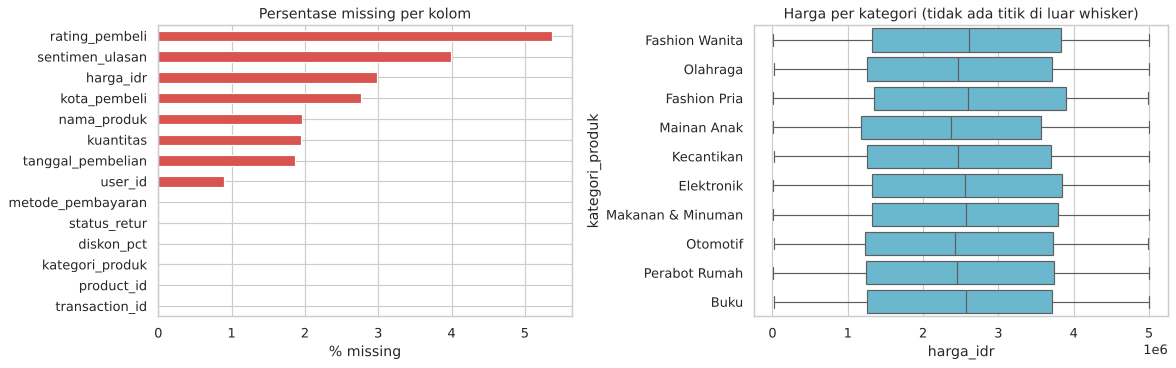

In [10]:
# (d) outlier IQR per kategori untuk semua kolom numerik
kol_num = ['harga_idr', 'kuantitas', 'diskon_pct', 'rating_pembeli']
n_out = {k: int(flag_outlier_iqr(df_mentah, k, 'kategori_produk')[0].sum()) for k in kol_num}
print('Jumlah outlier IQR per kategori:', n_out)
print('Transaksi dengan harga < Rp100.000:', int((df_mentah['harga_idr'] < 100_000).sum()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
audit['pct_missing'].sort_values().plot.barh(ax=ax[0], color='#d9534f')
ax[0].set_title('Persentase missing per kolom'); ax[0].set_xlabel('% missing')
sns.boxplot(data=df_mentah, y='kategori_produk', x='harga_idr', ax=ax[1], color='#5bc0de')
ax[1].set_title('Harga per kategori (tidak ada titik di luar whisker)'); ax[1].set_xlabel('harga_idr')
plt.tight_layout(); plt.show()

**Temuan audit (data mentah)**
- **Duplikat: tidak ada** (0 berdasarkan `transaction_id`, 0 berdasarkan isi baris).
- **Missing: 2.177 sel di 8 kolom**, mengenai 1.997 baris (sekitar 20% data). Terbanyak `rating_pembeli` (5,4%), `sentimen_ulasan` (4,0%), `harga_idr` (3,0%), `kota_pembeli` (2,8%), `nama_produk` dan `kuantitas` (masing-masing 2,0%), `tanggal_pembelian` (1,9%), dan `user_id` (0,9%).
- **Label sentimen kotor:** 3 makna ditulis dalam 11 variasi (mis. `Neg@tif`, `Netr@l`, `NETRAL`, `positif`), total 119 baris. Jika tidak dirapikan, model akan menganggap `Netral` dan `NETRAL` sebagai kategori berbeda.
- **Outlier IQR per kategori: 0** pada semua kolom numerik. Harga tersebar hampir seragam dari Rp10 ribu sampai Rp5 juta di semua kategori. Ada 159 transaksi dengan harga di bawah Rp100 ribu, tetapi itu bukan outlier statistik dan sesuai dengan sebaran seragam, jadi dipertahankan (pada data nyata, angka ini layak dikonfirmasi ke tim data).
- **Integritas `product_id` buruk:** satu `product_id` muncul rata-rata di 8,7 kategori dan 17,8 nama produk berbeda. Artinya `product_id` tidak bisa dipercaya sebagai identitas produk, sehingga analisis dilakukan di level kategori, bukan produk.

### Prinsip pembersihan
Urutan wajib: **duplikat → missing value → outlier → tipe data**. Satu langkah tambahan (2.0) dilakukan lebih dulu karena memengaruhi deteksi duplikat dan penanganan missing: merapikan penulisan label teks (spasi, huruf besar/kecil, karakter `@`). Langkah ini tidak mengubah jumlah baris.

**Prinsip anti-leakage dalam pembersihan:** pembersihan di sini hanya memakai aturan deterministik atau statistik **deskriptif** (median per kategori) yang tidak menyentuh target. Namun imputasi numerik dengan median yang dihitung dari seluruh data tetap "mengintip" baris yang nanti menjadi data uji. Karena itu saya menyimpan snapshot `df_pra_imputasi` (belum diimputasi numerik) khusus untuk tahap model, di mana imputasi dilakukan ulang di dalam `Pipeline` hanya dari data train (Tahap 4).

### 2.0 Normalisasi label
**Alasan:** label yang sama tetapi tertulis berbeda (`Neg@tif`, `NETRAL`, `positif`) dianggap kategori berbeda, sehingga `groupby`, encoding, dan aturan turunan menjadi salah. Fungsi `samakan_label` menyeragamkan huruf besar/kecil, spasi, dan karakter rusak `@` pada semua kolom teks selain ID, dengan ejaan yang paling sering muncul sebagai bentuk baku. Langkah ini tidak mengubah jumlah baris.

In [11]:
def samakan_label(s):
    s = s.str.strip()
    kunci = s.str.lower().str.replace('@', 'a', regex=False)
    kanon = s.groupby(kunci).agg(lambda x: x.value_counts().idxmax())
    return kunci.map(kanon).where(s.notna())

df = df_mentah.copy()
KOLOM_ID = ['transaction_id', 'user_id', 'product_id']
for c in KOLOM_ID:
    df[c] = df[c].str.strip()

kol_teks = [c for c in df.columns
            if not pd.api.types.is_numeric_dtype(df[c])
            and not pd.api.types.is_datetime64_any_dtype(df[c]) and c not in KOLOM_ID]
for c in kol_teks:
    sebelum = df[c].nunique()
    df[c] = samakan_label(df[c])
    if df[c].nunique() != sebelum:
        print(f'{c}: {sebelum} -> {df[c].nunique()} nilai unik')

print('\nLabel sentimen_ulasan setelah dinormalisasi:')
print(df['sentimen_ulasan'].value_counts(dropna=False).to_string())
assert set(df['sentimen_ulasan'].dropna().unique()) == {'Negatif', 'Netral', 'Positif'}, 'label sentimen tidak sesuai harapan'
assert set(df[KOLOM_TARGET].dropna().unique()) == {'Diretur', 'Tidak Diretur'}, 'label target tidak sesuai harapan'

sentimen_ulasan: 11 -> 3 nilai unik

Label sentimen_ulasan setelah dinormalisasi:
sentimen_ulasan
Negatif    3406
Netral     3266
Positif    2929
NaN         399


### 2a. Duplikat
**Alasan:** satu transaksi harus muncul satu kali agar bobotnya tidak ganda. Dicek dua kali: berdasarkan `transaction_id` (kunci) dan berdasarkan seluruh isi selain ID (transaksi yang sama tercatat ulang dengan ID baru). Jika ada, baris pertama dipertahankan.

In [12]:
n_awal = len(df)
df = df.drop_duplicates(subset='transaction_id', keep='first')
n_dup_kunci = n_awal - len(df)

kolom_isi = [c for c in df.columns if c != 'transaction_id']
n_sebelum = len(df)
df = df.drop_duplicates(subset=kolom_isi, keep='first')
n_dup_isi = n_sebelum - len(df)

print(f'Duplikat berdasarkan transaction_id : {n_dup_kunci}')
print(f'Duplikat berdasarkan isi baris      : {n_dup_isi}')
print(f'Baris tersisa                       : {len(df):,}')

Duplikat berdasarkan transaction_id : 0
Duplikat berdasarkan isi baris      : 0
Baris tersisa                       : 10,000


### 2b. Missing value
**Alasan** per kolom:

| Kolom | Keputusan | Alasan |
|---|---|---|
| Baris tanpa target `status_retur` | **Buang** | Tidak bisa dipakai belajar. Pada data ini 0 baris. |
| Kolom dengan missing > 50% | **Buang** | Informasinya terlalu sedikit. Pada data ini tidak ada. |
| `tanggal_pembelian` | **Buang baris** | Tanggal tidak bisa ditebak, dan dibutuhkan untuk tren waktu/RFM. Hanya ~1,9% baris. |
| `user_id` | Isi `TIDAK_DIKETAHUI` | Baris tetap valid sebagai transaksi, tetapi **dikeluarkan dari RFM** (tidak bisa dikaitkan ke pelanggan). |
| `nama_produk`, `kota_pembeli` | Isi `Tidak Diketahui` | Kolom kategorikal: "tidak diketahui" dijadikan kategori sendiri agar tidak ada baris hilang. |
| `sentimen_ulasan` | **Turunkan dari rating**; sisanya `Tidak Ada Ulasan` | Di data, sentimen mengikuti rating dengan batas jelas (Negatif ≤ 2,4; Netral 2,5–3,7; Positif ≥ 3,8). Aturan ini divalidasi di bawah. |
| `rating_pembeli` | **Dibiarkan kosong** + flag `rating_kosong` | Rating kosong berarti pembeli tidak memberi ulasan. Mengisinya dengan median akan mengarang opini. |
| `harga_idr`, `kuantitas` | Isi **median per kategori** (+ flag) | Dibutuhkan untuk menghitung nilai transaksi. Median tahan terhadap outlier. Untuk model, imputasi diulang di dalam Pipeline (hanya dari data train). |

In [13]:
# validasi aturan rating -> sentimen pada baris yang keduanya ada
def sentimen_dari_rating(r):
    return np.select([r <= 2.45, r <= 3.75], ['Negatif', 'Netral'], default='Positif')

ada = df['rating_pembeli'].notna() & df['sentimen_ulasan'].notna()
cocok = (sentimen_dari_rating(df.loc[ada, 'rating_pembeli']) == df.loc[ada, 'sentimen_ulasan']).mean()
print(f'Aturan rating -> sentimen cocok pada {cocok:.1%} dari {ada.sum():,} baris yang punya keduanya')

Aturan rating -> sentimen cocok pada 100.0% dari 9,082 baris yang punya keduanya


In [14]:
m0 = df.isnull().sum()

df = df.replace(r'^\s*$', np.nan, regex=True)        # teks kosong/spasi dianggap missing

n0 = len(df)
df = df.dropna(subset=[KOLOM_TARGET])
print(f'Baris target kosong dibuang: {n0 - len(df)}')

rasio = df.isnull().mean()
buang = [c for c in rasio[rasio > 0.5].index if c not in (KOLOM_TARGET, KOLOM_KUNCI)]
df = df.drop(columns=buang)
print('Kolom dibuang (>50% missing):', buang)


# a. buang baris tanpa tanggal
df = df.dropna(subset=['tanggal_pembelian'])

# b. kategorikal -> kategori "tidak diketahui"
df['user_id']     = df['user_id'].fillna('TIDAK_DIKETAHUI')
df['nama_produk'] = df['nama_produk'].fillna('Tidak Diketahui')
df['kota_pembeli'] = df['kota_pembeli'].fillna('Tidak Diketahui')

# c. sentimen: turunkan dari rating bila rating tersedia, sisanya "Tidak Ada Ulasan"
butuh = df['sentimen_ulasan'].isna() & df['rating_pembeli'].notna()
df.loc[butuh, 'sentimen_ulasan'] = sentimen_dari_rating(df.loc[butuh, 'rating_pembeli'])
n_turun = int(butuh.sum())
df['sentimen_ulasan'] = df['sentimen_ulasan'].fillna('Tidak Ada Ulasan')

# d. flag rating kosong (rating dibiarkan NaN)
df['rating_kosong'] = df['rating_pembeli'].isna().astype(int)

# --- SNAPSHOT untuk tahap model: numerik belum diimputasi (imputasi dilakukan setelah split) ---
df_pra_imputasi = df.copy()

# e. numerik -> median per kategori (hanya untuk keperluan analisis deskriptif)
df['harga_imputasi']    = df['harga_idr'].isna().astype(int)
df['kuantitas_imputasi'] = df['kuantitas'].isna().astype(int)
df['harga_idr'] = df['harga_idr'].fillna(df.groupby('kategori_produk')['harga_idr'].transform('median'))
df['kuantitas'] = df['kuantitas'].fillna(df.groupby('kategori_produk')['kuantitas'].transform('median')).round()

print(f'Sentimen diturunkan dari rating : {n_turun} baris')
print(f'Harga diimputasi                : {df["harga_imputasi"].sum()} baris')
print(f'Kuantitas diimputasi            : {df["kuantitas_imputasi"].sum()} baris')
print('\nMissing per kolom (sebelum -> sesudah):')
pd.DataFrame({'sebelum': m0, 'sesudah': df.isnull().sum()}).query('sebelum > 0 or sesudah > 0')

Baris target kosong dibuang: 0
Kolom dibuang (>50% missing): []
Sentimen diturunkan dari rating : 378 baris
Harga diimputasi                : 290 baris
Kuantitas diimputasi            : 191 baris

Missing per kolom (sebelum -> sesudah):


,sebelum,sesudah
harga_idr,298.00,0
kota_pembeli,276.00,0
kuantitas,195.00,0
nama_produk,196.00,0
rating_pembeli,537.00,520
sentimen_ulasan,399.00,0
tanggal_pembelian,187.00,0
user_id,89.00,0


### 2c. Outlier per grup
**Alasan:** sebaran harga bisa berbeda antar kategori, jadi batas IQR (1,5×) dihitung **per kategori**.
- `harga_idr` (kontinu): outlier di-**clip** ke batas IQR kategorinya (bukan dibuang, supaya baris transaksi tidak hilang). Jika tidak ada outlier, clipping tidak mengubah apa pun.
- `kuantitas`, `diskon_pct`, `rating_pembeli`: bersifat diskret dan terikat aturan bisnis, sehingga divalidasi dengan **rentang domain** (kuantitas 1–5, diskon 0–30%, rating 1–5), bukan IQR.

Fungsi dibuat sekali lalu dipakai juga pada `df_pra_imputasi` agar kedua versi data diperlakukan sama.

In [15]:
def tangani_outlier(d):
    d = d.copy()
    flag, lo, hi = flag_outlier_iqr(d, 'harga_idr', 'kategori_produk')
    n = int(flag.sum())
    d['harga_idr'] = d['harga_idr'].clip(lower=lo, upper=hi)
    # validasi rentang domain (error jika ada nilai tak wajar)
    assert d['kuantitas'].dropna().between(1, 5).all(),        'kuantitas di luar 1-5'
    assert d['diskon_pct'].between(0, 30).all(),               'diskon di luar 0-30'
    assert d['rating_pembeli'].dropna().between(1, 5).all(),   'rating di luar 1-5'
    assert (d['harga_idr'].dropna() > 0).all(),                'harga <= 0'
    return d, n

df, n_clip = tangani_outlier(df)
df_pra_imputasi, _ = tangani_outlier(df_pra_imputasi)
print(f'Outlier harga yang di-clip: {n_clip}')
print('Validasi rentang domain: lolos (kuantitas 1-5, diskon 0-30, rating 1-5, harga > 0)')

Outlier harga yang di-clip: 0
Validasi rentang domain: lolos (kuantitas 1-5, diskon 0-30, rating 1-5, harga > 0)


### 2d. Tipe data
**Alasan:** target diubah ke 0/1 agar siap untuk model, teks bernilai sedikit menjadi `category`, ID menjadi `string`, dan tanggal menjadi `datetime`.
ID → `string`; kolom bernilai terbatas → `category`; target `status_retur` → `retur` (1 = Diretur, 0 = Tidak Diretur); tanggal → `datetime`.
Fitur turunan dihitung **per baris** (tidak memakai informasi baris lain), sehingga aman dari leakage: `total_bayar`, `tahun`, `bulan`, `kuartal`, `hari_minggu`, `akhir_pekan`.

In [16]:
def perbaiki_tipe(d):
    d = d.copy()
    for k in ['transaction_id', 'user_id', 'product_id', 'nama_produk']:
        d[k] = d[k].astype('string')
    for k in ['kategori_produk', 'metode_pembayaran', 'kota_pembeli', 'sentimen_ulasan', 'status_retur']:
        d[k] = d[k].astype('category')
    d['tanggal_pembelian'] = pd.to_datetime(d['tanggal_pembelian'])
    d['diskon_pct'] = d['diskon_pct'].astype('int16')
    if d['kuantitas'].notna().all():
        d['kuantitas'] = d['kuantitas'].astype('int16')
    d['retur'] = (d['status_retur'].astype(str) == 'Diretur').astype('int8')
    # fitur turunan (per baris)
    d['total_bayar']  = (d['harga_idr'] * d['kuantitas'] * (1 - d['diskon_pct'] / 100)).round(2)
    d['tahun']        = d['tanggal_pembelian'].dt.year
    d['bulan']        = d['tanggal_pembelian'].dt.month
    d['kuartal']      = d['tanggal_pembelian'].dt.quarter
    d['hari_minggu']  = d['tanggal_pembelian'].dt.dayofweek          # 0 = Senin
    d['akhir_pekan']  = (d['hari_minggu'] >= 5).astype('int8')
    return d

df = perbaiki_tipe(df)
df_pra_imputasi = perbaiki_tipe(df_pra_imputasi)

urutan = ['transaction_id', 'user_id', 'product_id', 'kategori_produk', 'nama_produk',
          'harga_idr', 'kuantitas', 'diskon_pct', 'total_bayar',
          'rating_pembeli', 'sentimen_ulasan',
          'tanggal_pembelian', 'tahun', 'bulan', 'kuartal', 'hari_minggu', 'akhir_pekan',
          'metode_pembayaran', 'kota_pembeli', 'status_retur', 'retur']
df_pra_imputasi = df_pra_imputasi[urutan + ['rating_kosong']]
df_bersih = df[urutan + ['harga_imputasi', 'kuantitas_imputasi', 'rating_kosong']].copy()

assert df_bersih.index.equals(df_pra_imputasi.index)
print('df_bersih      :', df_bersih.shape)
print('df_pra_imputasi:', df_pra_imputasi.shape)
df_bersih.dtypes.to_frame('tipe')

df_bersih      : (9813, 24)
df_pra_imputasi: (9813, 22)


,tipe
transaction_id,string
user_id,string
product_id,string
kategori_produk,category
nama_produk,string
harga_idr,float64
kuantitas,int16
diskon_pct,int16
total_bayar,float64
rating_pembeli,float64


### Tabel kualitas sebelum vs sesudah
`tugas-hands-on-3/laporan_kualitas.csv` berisi tabel persis seperti kerangka tugas (empat metrik `cek_kualitas`, kolom `sebelum` dan `sesudah`). Tiga metrik tambahan dan kolom `selisih` hanya ditampilkan di notebook untuk membantu interpretasi.

In [17]:
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, KOLOM_NUM, KOLOM_GRUP, KOLOM_KUNCI),
    'sesudah': cek_kualitas(df_bersih, KOLOM_NUM, KOLOM_GRUP, KOLOM_KUNCI),
})
laporan.to_csv(f'{BASE}/laporan_kualitas.csv')          # file yang dikumpulkan: 4 metrik wajib

# tampilan lengkap untuk interpretasi (tidak disimpan ke CSV)
tambahan = pd.DataFrame({'sebelum': cek_tambahan(df_mentah), 'sesudah': cek_tambahan(df_bersih)})
laporan_lengkap = pd.concat([laporan, tambahan])
laporan_lengkap['selisih'] = laporan_lengkap['sesudah'] - laporan_lengkap['sebelum']
laporan_lengkap

,sebelum,sesudah,selisih
n_baris,10000,9813,-187
n_duplikat,0,0,0
n_missing,2177,520,-1657
n_outlier,0,0,0
n_baris_ada_missing,1997,520,-1477
n_kolom_ada_missing,8,1,-7
n_label_sentimen_unik,11,4,-7


In [18]:
# rincian missing yang masih tersisa setelah pembersihan
sisa = df_bersih.isnull().sum()
sisa[sisa > 0].to_frame('n_missing_tersisa')

,n_missing_tersisa
rating_pembeli,520


**Interpretasi:**
| Metrik | Sebelum → Sesudah | Penjelasan |
|---|---|---|
| `n_baris` | 10.000 → 9.813 | 187 baris (1,9%) dibuang karena tidak punya tanggal. Itu satu-satunya baris yang hilang. |
| `n_duplikat` | 0 → 0 | Tidak ada duplikat. Pemeriksaan tetap dijalankan sebagai kode agar pembersihan bisa diulang pada data baru. |
| `n_missing` | 2.177 → 520 (turun 76%) | Sisa 520 sel **semuanya** `rating_pembeli`, sengaja dibiarkan kosong karena artinya pembeli tidak memberi ulasan (ditandai `rating_kosong`). Pada tahap model, kekosongan ini ditangani imputer di dalam Pipeline. |
| `n_outlier` | 0 → 0 | Tidak ada outlier harga per kategori, sehingga clipping tidak mengubah data. Kolom numerik lain juga 0 (lihat §2.2). |
| `n_baris_ada_missing` | 1.997 → 520 | Baris yang bersih dari missing naik dari 80% menjadi 95%. |
| `n_kolom_ada_missing` | 8 → 1 | Hanya `rating_pembeli` yang masih memuat NaN. |
| `n_label_sentimen_unik` | 11 → 4 | Tiga label baku ditambah `Tidak Ada Ulasan`. |

Kesimpulan: masalah utama dataset ini adalah **missing value dan label teks yang tidak konsisten**, bukan duplikat atau outlier.

## 3. Analisis
Dataset punya pelanggan (`user_id`), transaksi, tanggal, dan target retur, sehingga analisis mencakup: groupby lanjutan, reshape (pivot/melt), tren waktu, dan RFM. "Nilai transaksi" di bagian ini adalah `total_bayar` (harga × kuantitas × (1 − diskon)).

### 3.1 Groupby lanjutan: ringkasan per kategori
Memakai *named aggregation* agar kolom hasil mudah dibaca.

In [19]:
print(f'Tingkat retur keseluruhan: {df_bersih["retur"].mean():.1%}')

ringkas_kat = (df_bersih.groupby('kategori_produk', observed=True)
    .agg(n_transaksi=('transaction_id', 'count'),
         gmv_miliar=('total_bayar', lambda s: s.sum() / 1e9),
         rata_nilai_juta=('total_bayar', lambda s: s.mean() / 1e6),
         rata_diskon=('diskon_pct', 'mean'),
         rata_rating=('rating_pembeli', 'mean'),
         retur_rate=('retur', 'mean'))
    .sort_values('retur_rate', ascending=False))
ringkas_kat['retur_rate'] = ringkas_kat['retur_rate'] * 100
ringkas_kat.rename(columns={'retur_rate': 'retur_%'})

Tingkat retur keseluruhan: 22.4%


,n_transaksi,gmv_miliar,rata_nilai_juta,rata_diskon,rata_rating,retur_%
kategori_produk,,,,,,
Kecantikan,932,5.93,6.36,13.36,2.92,24.46
Otomotif,1015,6.62,6.52,13.24,3.00,23.65
Fashion Wanita,956,6.46,6.76,13.25,3.00,23.01
Makanan & Minuman,955,6.45,6.75,13.30,2.99,22.72
Fashion Pria,1003,6.93,6.91,12.99,3.05,22.13
Perabot Rumah,1018,6.77,6.65,13.13,3.04,22.00
Mainan Anak,1006,6.29,6.25,13.07,2.98,21.77
Buku,971,6.28,6.47,13.02,3.02,21.73
Olahraga,980,6.20,6.33,12.97,2.98,21.43


### 3.2 Apa yang berkaitan dengan retur?
Tingkat retur dibandingkan berdasarkan beberapa dimensi, lalu **uji chi-square** dipakai untuk membedakan perbedaan yang nyata dari kebetulan (angka bisa terlihat beda padahal hanya noise, terutama pada kelompok kecil).

In [20]:
d_uji = df_bersih.assign(
    kelompok_harga=pd.qcut(df_bersih['harga_idr'], 5,
        labels=['Q1 termurah', 'Q2', 'Q3', 'Q4', 'Q5 termahal']))

def uji_chi2(d, kolom):
    tabel = pd.crosstab(d[kolom], d['retur'])
    chi2, p, dof, _ = stats.chi2_contingency(tabel)
    return pd.Series({'chi2': chi2, 'dof': dof, 'p_value': p})

kandidat = ['kelompok_harga', 'kategori_produk', 'metode_pembayaran', 'kota_pembeli',
            'diskon_pct', 'kuantitas', 'bulan', 'hari_minggu', 'sentimen_ulasan']
uji = pd.DataFrame({k: uji_chi2(d_uji, k) for k in kandidat}).T
uji['signifikan_5%'] = np.where(uji['p_value'] < 0.05, 'ya', 'tidak')
uji.sort_values('p_value')

,chi2,dof,p_value,signifikan_5%
sentimen_ulasan,"1,726.56",3.00,0.00,ya
kelompok_harga,46.17,4.00,0.00,ya
bulan,12.01,11.00,0.36,tidak
hari_minggu,5.08,6.00,0.53,tidak
kota_pembeli,6.31,10.00,0.79,tidak
metode_pembayaran,1.04,3.00,0.79,tidak
kuantitas,1.54,4.00,0.82,tidak
kategori_produk,5.16,9.00,0.82,tidak
diskon_pct,1.55,6.00,0.96,tidak


,n,harga_min,harga_max,retur_pct
kelompok_harga,,,,
Q1 termurah,1963,"10,025.00","1,060,297.00",18.44
Q2,1962,"1,060,654.00","2,094,833.00",19.57
Q3,1963,"2,095,042.00","2,947,934.00",23.74
Q4,1962,"2,949,226.00","3,988,462.00",25.38
Q5 termahal,1963,"3,988,588.00","4,999,941.00",24.96


,count,mean,median
status_retur,,,
Diretur,2085,2.10,1.90
Tidak Diretur,7208,3.26,3.40


status_retur,Diretur,Tidak Diretur
sentimen_ulasan,,
Negatif,45.55,54.45
Netral,13.90,86.10
Positif,5.05,94.95
Tidak Ada Ulasan,23.53,76.47


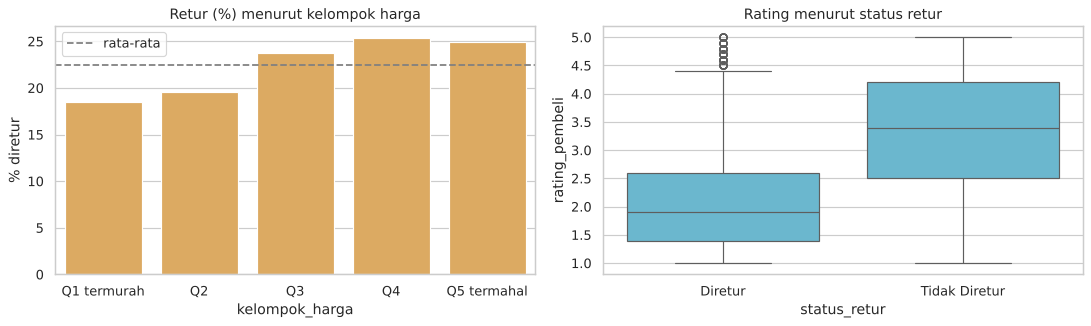

In [21]:
retur_harga = (d_uji.groupby('kelompok_harga', observed=True)
    .agg(n=('retur', 'size'), harga_min=('harga_idr', 'min'), harga_max=('harga_idr', 'max'), retur_pct=('retur', 'mean')))
retur_harga['retur_pct'] *= 100

# rating antara transaksi yang diretur dan tidak
retur_rating = df_bersih.groupby('status_retur', observed=True)['rating_pembeli'].agg(['count', 'mean', 'median'])
retur_sent = pd.crosstab(df_bersih['sentimen_ulasan'], df_bersih['status_retur'], normalize='index') * 100

display(retur_harga)
display(retur_rating)
display(retur_sent)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=retur_harga.index, y=retur_harga['retur_pct'], ax=ax[0], color='#f0ad4e')
ax[0].axhline(df_bersih['retur'].mean() * 100, ls='--', c='grey', label='rata-rata')
ax[0].set_title('Retur (%) menurut kelompok harga'); ax[0].set_ylabel('% diretur'); ax[0].legend()
sns.boxplot(data=df_bersih, x='status_retur', y='rating_pembeli', ax=ax[1], color='#5bc0de')
ax[1].set_title('Rating menurut status retur')
plt.tight_layout(); plt.show()

**Ambang harga.** Tabel kelompok harga menunjukkan lonjakan retur di antara Q2 dan Q3 (sekitar Rp2 juta). Berikut perbandingan di bawah vs di atas Rp2 juta, termasuk perkiraan nilai retur yang bisa dihindari jika segmen mahal diturunkan ke tingkat retur segmen murah. (Ambang dipilih dari pengamatan eksploratif dan **tidak** dipakai sebagai fitur model; ini perkiraan kasar, bukan prediksi.)

In [22]:
AMBANG = 2_000_000
d_amb = df_bersih.assign(kelompok=np.where(df_bersih['harga_idr'] >= AMBANG, '>= Rp2 juta', '< Rp2 juta'),
                         nilai_retur=df_bersih['total_bayar'] * df_bersih['retur'])
tab_amb = d_amb.groupby('kelompok').agg(n_transaksi=('retur', 'size'),
                                        retur_pct=('retur', lambda s: s.mean() * 100),
                                        n_retur=('retur', 'sum'),
                                        nilai_retur_miliar=('nilai_retur', lambda s: s.sum() / 1e9))
tab_amb['%_dari_transaksi'] = tab_amb['n_transaksi'] / tab_amb['n_transaksi'].sum() * 100
tab_amb['%_dari_nilai_retur'] = tab_amb['nilai_retur_miliar'] / tab_amb['nilai_retur_miliar'].sum() * 100
p_amb = stats.chi2_contingency(pd.crosstab(d_amb['kelompok'], d_amb['retur']))[1]

mahal, murah = tab_amb.loc['>= Rp2 juta'], tab_amb.loc['< Rp2 juta']
retur_dihindari = mahal['n_transaksi'] * (mahal['retur_pct'] - murah['retur_pct']) / 100
nilai_dihindari = mahal['nilai_retur_miliar'] * (1 - murah['retur_pct'] / mahal['retur_pct'])
print(f'p-value chi-square (di bawah vs di atas Rp2 juta): {p_amb:.2e}')
print(f'Jika retur segmen >= Rp2 juta turun ke {murah["retur_pct"]:.1f}%: ~{retur_dihindari:,.0f} retur / ~Rp{nilai_dihindari:.1f} miliar '
      f'(selama {df_bersih["tahun"].nunique()} tahun) bisa dihindari')
tab_amb

p-value chi-square (di bawah vs di atas Rp2 juta): 7.48e-11
Jika retur segmen >= Rp2 juta turun ke 18.9%: ~344 retur / ~Rp3.1 miliar (selama 3 tahun) bisa dihindari


,n_transaksi,retur_pct,n_retur,nilai_retur_miliar,%_dari_transaksi,%_dari_nilai_retur
kelompok,,,,,,
< Rp2 juta,3743,18.92,708,1.80,38.14,11.84
>= Rp2 juta,6070,24.58,1492,13.40,61.86,88.16


### 3.3 Reshape: pivot dan melt
`pivot_table` membentuk matriks kategori × metode pembayaran; `melt` mengubahnya kembali ke format panjang untuk mengurutkan kombinasi dengan retur tertinggi. Kombinasi memuat sekitar 250 transaksi per sel, jadi perbedaannya perlu dibaca hati-hati.

,kategori_produk,metode_pembayaran,retur_pct
24,Kecantikan,Kartu Kredit,28.31
0,Buku,COD,27.07
38,Otomotif,Transfer Bank,25.82
14,Kecantikan,Dompet Digital,25.42
6,Makanan & Minuman,COD,25.23


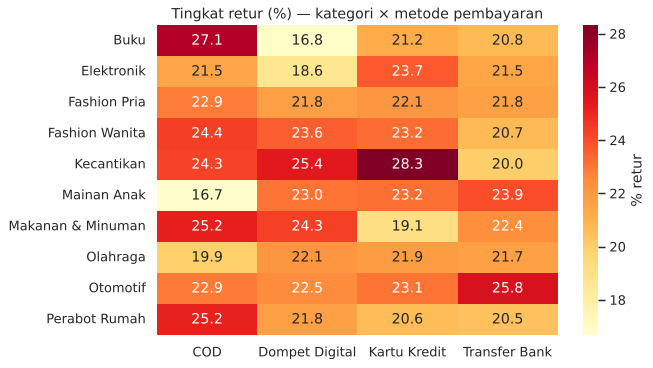

In [23]:
pivot_retur = df_bersih.pivot_table(index='kategori_produk', columns='metode_pembayaran',
                                    values='retur', aggfunc='mean', observed=True) * 100

plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot_retur, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': '% retur'})
plt.title('Tingkat retur (%) — kategori × metode pembayaran'); plt.ylabel(''); plt.xlabel('')
plt.tight_layout(); plt.show()

panjang = (pivot_retur.reset_index()
           .melt(id_vars='kategori_produk', var_name='metode_pembayaran', value_name='retur_pct')
           .sort_values('retur_pct', ascending=False))
panjang.head(5)

### 3.4 Tren waktu
Data harian diagregasi ke bulanan dengan `resample('MS')`, lalu dihaluskan dengan rata-rata bergerak 3 bulan untuk melihat arah tren di balik fluktuasi acak.

,n_transaksi,gmv_miliar,retur_pct,pertumbuhan_gmv_%
tahun,,,,
2022,3285,21.40,23.01,NaN
2023,3296,21.58,21.69,0.82
2024,3232,21.33,22.56,-1.16


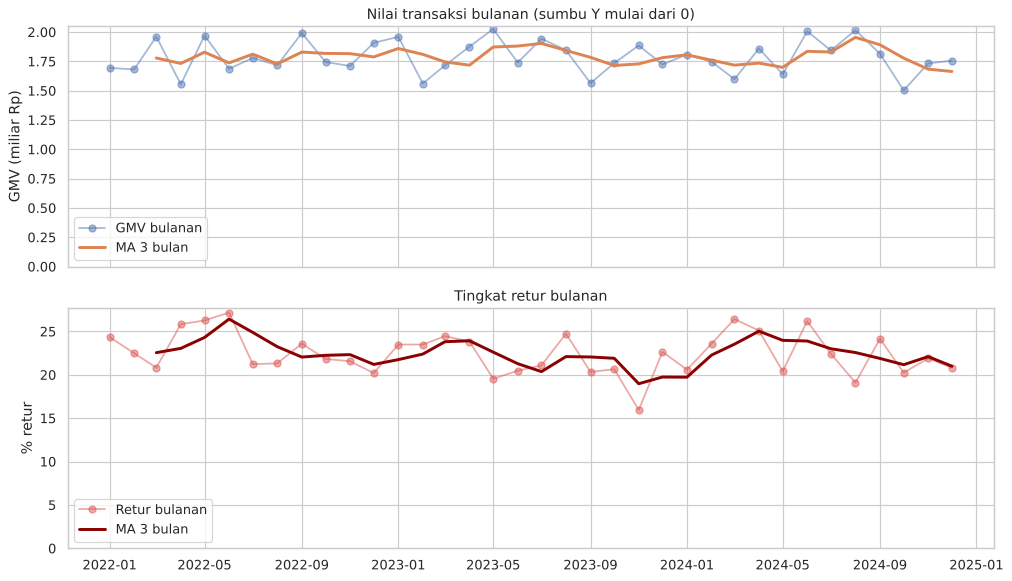

In [24]:
bulanan = (df_bersih.set_index('tanggal_pembelian').sort_index()
           .resample('MS')
           .agg(n_transaksi=('transaction_id', 'count'),
                gmv_miliar=('total_bayar', lambda s: s.sum() / 1e9),
                retur_pct=('retur', lambda s: s.mean() * 100)))
bulanan['gmv_ma3']   = bulanan['gmv_miliar'].rolling(3).mean()
bulanan['retur_ma3'] = bulanan['retur_pct'].rolling(3).mean()

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(bulanan.index, bulanan['gmv_miliar'], marker='o', alpha=.5, label='GMV bulanan')
ax[0].plot(bulanan.index, bulanan['gmv_ma3'], lw=2.5, label='MA 3 bulan')
ax[0].set_ylim(0, None); ax[0].set_ylabel('GMV (miliar Rp)'); ax[0].set_title('Nilai transaksi bulanan (sumbu Y mulai dari 0)'); ax[0].legend()
ax[1].plot(bulanan.index, bulanan['retur_pct'], marker='o', alpha=.5, c='#d9534f', label='Retur bulanan')
ax[1].plot(bulanan.index, bulanan['retur_ma3'], lw=2.5, c='#8b0000', label='MA 3 bulan')
ax[1].set_ylim(0, None); ax[1].set_ylabel('% retur'); ax[1].set_title('Tingkat retur bulanan'); ax[1].legend()
plt.tight_layout(); plt.show()

tahunan = df_bersih.groupby('tahun').agg(n_transaksi=('transaction_id', 'count'),
                                         gmv_miliar=('total_bayar', lambda s: s.sum() / 1e9),
                                         retur_pct=('retur', lambda s: s.mean() * 100))
tahunan['pertumbuhan_gmv_%'] = tahunan['gmv_miliar'].pct_change() * 100
tahunan

In [25]:
# pola musiman: rata-rata GMV per bulan kalender dan per hari dalam seminggu
musim = df_bersih.groupby('bulan').agg(gmv_miliar=('total_bayar', lambda s: s.sum() / 1e9 / 3))   # rata-rata per tahun
hari  = df_bersih.groupby('hari_minggu').agg(n_transaksi=('transaction_id', 'count'), retur_pct=('retur', lambda s: s.mean() * 100))
hari.index = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
display(musim.T)
display(hari.T)
print('Koefisien variasi GMV bulanan (std/mean):', round(bulanan['gmv_miliar'].std() / bulanan['gmv_miliar'].mean(), 3))

bulan,1,2,3,4,5,6,7,8,9,10,11,12
gmv_miliar,1.82,1.66,1.76,1.76,1.88,1.81,1.86,1.86,1.79,1.66,1.78,1.80


,Sen,Sel,Rab,Kam,Jum,Sab,Min
n_transaksi,"1,442.00","1,386.00","1,369.00","1,435.00","1,371.00","1,390.00","1,420.00"
retur_pct,22.26,20.78,21.62,23.48,22.17,23.67,22.89


Koefisien variasi GMV bulanan (std/mean): 0.08


### 3.5 RFM dan segmentasi pelanggan
- **Recency** = hari sejak transaksi terakhir (acuan: sehari setelah tanggal terakhir di data), **Frequency** = jumlah transaksi, **Monetary** = total `total_bayar`.
- Transaksi dengan `user_id` tidak diketahui **dikeluarkan** (tidak bisa dikaitkan ke pelanggan).
- Skor 1–5: Recency dan Monetary memakai kuintil (`rank(method='first')` untuk mematahkan *tie*); Frequency memakai batas tetap (1, 2, 3, 4, ≥5 transaksi) karena nilainya diskret dan banyak yang sama.
- RFM di sini bersifat **deskriptif**; segmen tidak dipakai sebagai fitur model sehingga tidak ada leakage.

In [26]:
d_rfm = df_bersih[df_bersih['user_id'] != 'TIDAK_DIKETAHUI']
tgl_ref = d_rfm['tanggal_pembelian'].max() + pd.Timedelta(days=1)

rfm = d_rfm.groupby('user_id').agg(
    recency=('tanggal_pembelian', lambda s: (tgl_ref - s.max()).days),
    frequency=('transaction_id', 'nunique'),
    monetary=('total_bayar', 'sum'))

rfm['R'] = pd.qcut(rfm['recency'].rank(method='first'),  5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F'] = pd.cut(rfm['frequency'], bins=[0, 1, 2, 3, 4, np.inf], labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

kondisi = [(rfm.R >= 4) & (rfm.F >= 4),
           (rfm.R <= 2) & (rfm.F >= 4),
           (rfm.F >= 4),
           (rfm.R >= 4) & (rfm.F == 1),
           (rfm.R >= 4),
           (rfm.R <= 2) & (rfm.F <= 2)]
nama_segmen = ['Champions', 'Berisiko (loyal, lama tak beli)', 'Loyal',
               'Pelanggan baru', 'Potensial', 'Hibernasi']
rfm['segmen'] = np.select(kondisi, nama_segmen, default='Perlu perhatian')

print(f'Pelanggan teridentifikasi: {len(rfm):,} | tanggal acuan: {tgl_ref.date()}')
rfm[['recency', 'frequency', 'monetary']].describe().T

Pelanggan teridentifikasi: 2,888 | tanggal acuan: 2025-01-01


,count,mean,std,min,25%,50%,75%,max
recency,"2,888.00",296.88,252.19,1.00,96.00,220.00,436.00,"1,091.00"
frequency,"2,888.00",3.37,1.70,1.00,2.00,3.00,4.00,11.00
monetary,"2,888.00","22,071,422.45","14,809,938.28","71,084.25","10,994,975.51","19,643,025.27","30,433,763.98","87,408,691.40"


,n_pelanggan,rata_recency_hari,rata_frequency,total_monetary_miliar,%_pelanggan,%_nilai
segmen,,,,,,
Champions,662,75.69,5.16,22.45,22.92,35.22
Perlu perhatian,545,355.02,2.65,9.34,18.87,14.66
Loyal,282,219.23,4.97,9.34,9.76,14.65
"Berisiko (loyal, lama tak beli)",296,444.21,4.57,8.94,10.25,14.02
Potensial,429,83.14,2.59,7.31,14.85,11.47
Hibernasi,610,622.22,1.53,6.05,21.12,9.49
Pelanggan baru,64,82.17,1.00,0.31,2.22,0.49


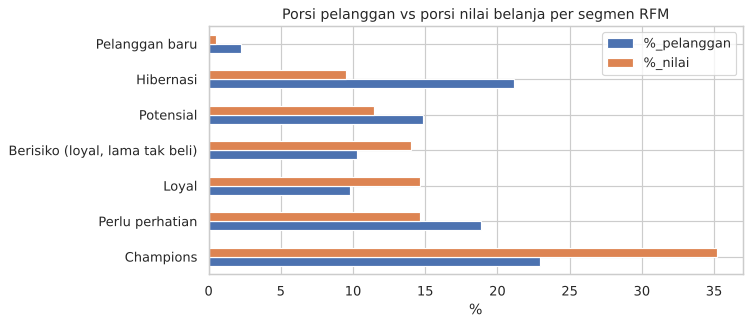

In [27]:
profil_segmen = (rfm.groupby('segmen')
    .agg(n_pelanggan=('monetary', 'size'),
         rata_recency_hari=('recency', 'mean'),
         rata_frequency=('frequency', 'mean'),
         total_monetary_miliar=('monetary', lambda s: s.sum() / 1e9)))
profil_segmen['%_pelanggan'] = profil_segmen['n_pelanggan'] / profil_segmen['n_pelanggan'].sum() * 100
profil_segmen['%_nilai']     = profil_segmen['total_monetary_miliar'] / profil_segmen['total_monetary_miliar'].sum() * 100
profil_segmen = profil_segmen.sort_values('%_nilai', ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
profil_segmen[['%_pelanggan', '%_nilai']].plot.barh(ax=ax)
ax.set_title('Porsi pelanggan vs porsi nilai belanja per segmen RFM'); ax.set_xlabel('%'); ax.set_ylabel('')
plt.tight_layout(); plt.show()
profil_segmen

In [28]:
# konsentrasi nilai: berapa persen belanja datang dari 20% pelanggan teratas?
m_sorted = rfm['monetary'].sort_values(ascending=False)
top20 = m_sorted.head(int(len(m_sorted) * 0.2)).sum() / m_sorted.sum() * 100
print(f'20% pelanggan teratas menyumbang {top20:.1f}% dari total nilai belanja')

20% pelanggan teratas menyumbang 40.9% dari total nilai belanja


### 3.6 Clustering KMeans pada RFM
Sebagai pembanding aturan manual, pelanggan dikelompokkan dengan KMeans pada Recency, Frequency, dan log(Monetary) yang distandarkan. Jumlah klaster dipilih dengan **silhouette score** (k = 2–6). Standardisasi di sini bersifat eksploratif pada seluruh pelanggan (tidak ada target yang diprediksi, jadi tidak ada risiko leakage).

In [29]:
Z = StandardScaler().fit_transform(np.column_stack([rfm['recency'], rfm['frequency'], np.log1p(rfm['monetary'])]))

hasil_k = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    hasil_k[k] = silhouette_score(Z, km.labels_)
sil = pd.Series(hasil_k, name='silhouette')
k_terbaik = int(sil.idxmax())
print(sil.round(3).to_string())
print(f'\nk terpilih = {k_terbaik}')

rfm['klaster'] = KMeans(n_clusters=k_terbaik, n_init=10, random_state=SEED).fit_predict(Z)
(rfm.groupby('klaster').agg(n_pelanggan=('monetary', 'size'), recency=('recency', 'mean'),
                            frequency=('frequency', 'mean'), monetary_juta=('monetary', lambda s: s.mean() / 1e6)))

2   0.39
3   0.32
4   0.33
5   0.33
6   0.32

k terpilih = 2


,n_pelanggan,recency,frequency,monetary_juta
klaster,,,,
0,1091,488.75,1.86,9.98
1,1797,180.39,4.28,29.41


### 3.7 Tiga temuan yang bisa ditindaklanjuti
Tingkat retur keseluruhan adalah **22,4%**.

1. **Barang ≥ Rp2 juta diretur 24,6%, vs 18,9% untuk barang di bawahnya. Barang mahal hanya 62% transaksi tetapi 88% nilai retur (Rp13,4 dari Rp15,2 miliar)** → perketat QC pra-kirim dan perjelas foto/deskripsi/ukuran pada produk ≥ Rp2 juta. Jika retur segmen ini turun ke 18,9%, sekitar 340 retur (≈ Rp3 miliar dalam 3 tahun) bisa dihindari (perkiraan kasar).
2. **Transaksi yang diretur punya rating rata-rata 2,1 vs 3,3 yang tidak diretur; ulasan *Negatif* berakhir retur 45,6% vs 5,1% pada *Positif*** → buat antrean CS proaktif untuk rating ≤ 2,4. Syaratnya ulasan terbit *sebelum* retur; data tidak punya cap waktu, jadi urutannya harus dicek dulu.
3. **GMV tahunan datar (Rp21,4 → 21,6 → 21,3 miliar) dan tanpa pola musiman, sementara 296 pelanggan setia yang lama tak membeli (segmen *Berisiko*) menyimpan 14% nilai belanja** → arahkan pertumbuhan ke retensi: kampanye win-back untuk 296 pelanggan itu, dan program loyalitas untuk *Champions* (23% pelanggan, 35% nilai).

**Catatan:** kategori, kota, metode bayar, diskon, kuantitas, bulan, dan hari tidak berkaitan nyata dengan retur (chi-square, p = 0,36–0,96). Selisih antar kategori (21,4%–24,5%) hanyalah fluktuasi acak, jadi program pengurangan retur per kategori atau kota tidak punya dasar data.

## 4. Persiapan Model
Split dulu (dengan `stratify=y`), baru imputasi, scaling, dan encoding lewat `ColumnTransformer` yang di-`fit` hanya pada data train.

**Target:** `retur` (1 = Diretur). Proporsinya tidak seimbang (sekitar seperempat), sehingga split memakai `stratify=y`.

**Pemilihan fitur dan risiko leakage:**
- Dibuang: `transaction_id`, `user_id`, `product_id` (pengenal; `product_id` juga tidak konsisten dengan kategori/nama), `nama_produk` (hanya "Produk #n", tidak informatif), `total_bayar` (turunan harga × kuantitas × diskon, redundan), `status_retur` (itu targetnya sendiri).
- **`rating_pembeli` dan `sentimen_ulasan` dianggap berisiko leakage**: keduanya baru ada *setelah* barang diterima, yaitu pada saat yang sama atau setelah keputusan retur. Model yang memakainya akan tampak bagus tetapi tidak bisa dipakai untuk memprediksi retur *sebelum* terjadi. Skenario **A** (tanpa keduanya) adalah model yang sah dipakai; skenario **B** (dengan keduanya) hanya pembanding untuk menunjukkan besarnya efek tersebut. Di dalam A, **A1** hanya memakai fitur numerik dan **A2** menambah fitur kategorikal; keduanya dibandingkan dengan *cross-validation pada train* (bukan dari p-value seluruh data) agar pemilihan fitur tidak membocorkan data uji.

**Urutan yang benar:** split → (imputasi, scaling, encoding di-*fit* hanya pada train). Semuanya dibungkus `ColumnTransformer` di dalam `Pipeline`, sehingga bahkan saat cross-validation, preprocessing di-fit ulang pada tiap fold-train.
Data yang dipakai adalah `df_pra_imputasi` (numerik masih punya NaN), bukan `df_bersih`.

**Catatan jujur:** langkah pembersihan (normalisasi label, batas clip outlier) dihitung sebelum split sesuai urutan tugas. Pada dataset ini tidak ada nilai yang di-clip (0 outlier), sehingga tidak ada pengaruh ke data uji; imputasi numerik, yang memang berpengaruh, dipindahkan ke dalam Pipeline setelah split.

In [30]:
FITUR_NUM_A = ['harga_idr', 'kuantitas', 'diskon_pct', 'akhir_pekan']
FITUR_CAT_A = ['kategori_produk', 'metode_pembayaran', 'kota_pembeli', 'bulan']
FITUR_NUM_B = FITUR_NUM_A + ['rating_pembeli']
FITUR_CAT_B = FITUR_CAT_A + ['sentimen_ulasan']

SEMUA = sorted(set(FITUR_NUM_B + FITUR_CAT_B))
X = df_pra_imputasi[SEMUA].copy()
for k in FITUR_CAT_B:                       # kategorikal -> object agar kompatibel dengan SimpleImputer/OneHotEncoder
    X[k] = X[k].astype(str).astype(object)
y = df_pra_imputasi['retur']

# 1) SPLIT DULU
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Proporsi retur -> seluruh data: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}')
print('\nMissing pada X_train (akan ditangani imputer di dalam Pipeline):')
X_train.isnull().sum()[lambda s: s > 0].to_frame('n_missing')

Train: (7850, 10) | Test: (1963, 10)
Proporsi retur -> seluruh data: 0.2242 | train: 0.2242 | test: 0.2241

Missing pada X_train (akan ditangani imputer di dalam Pipeline):


,n_missing
harga_idr,235
kuantitas,153
rating_pembeli,404


In [31]:
def buat_preprocessor(num, cat):
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                         ('scaler',  StandardScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer([('num', num_pipe, num), ('cat', cat_pipe, cat)])

# 2) FIT preprocessor hanya pada TRAIN, lalu transform train dan test
prep = buat_preprocessor(FITUR_NUM_A, FITUR_CAT_A)
Xt_train = prep.fit_transform(X_train[FITUR_NUM_A + FITUR_CAT_A])
Xt_test  = prep.transform(X_test[FITUR_NUM_A + FITUR_CAT_A])
print('Hasil transformasi -> train:', Xt_train.shape, '| test:', Xt_test.shape)

Hasil transformasi -> train: (7850, 43) | test: (1963, 43)


**Bukti tidak ada leakage:** statistik imputer dan scaler dihitung hanya dari data train, lalu dipakai apa adanya untuk data test. Pemeriksaan di bawah memakai `assert`, jadi sel akan gagal jika ada kebocoran.

In [32]:
# statistik harus berasal dari TRAIN, bukan dari seluruh data
scaler = prep.named_transformers_['num'].named_steps['scaler']
n = len(FITUR_NUM_A)
rata_train = X_train[FITUR_NUM_A].fillna(X_train[FITUR_NUM_A].median()).mean().values
rata_semua = X[FITUR_NUM_A].fillna(X[FITUR_NUM_A].median()).mean().values
imputer = prep.named_transformers_['num'].named_steps['imputer']
assert np.allclose(imputer.statistics_, X_train[FITUR_NUM_A].median().values), 'imputer tidak di-fit pada train!'
assert np.allclose(scaler.mean_[:n], rata_train), 'scaler tidak di-fit pada train!'
assert set(X_train.index).isdisjoint(X_test.index), 'train dan test beririsan!'
print('\nCek leakage: median imputer == median TRAIN, mean scaler == mean TRAIN, train/test tidak beririsan  ->  LOLOS')
print(pd.DataFrame({'mean_scaler': scaler.mean_[:n], 'mean_train': rata_train, 'mean_seluruh_data': rata_semua}, index=FITUR_NUM_A))


Cek leakage: median imputer == median TRAIN, mean scaler == mean TRAIN, train/test tidak beririsan  ->  LOLOS
             mean_scaler   mean_train  mean_seluruh_data
harga_idr   2,509,222.19 2,509,222.19       2,513,406.97
kuantitas           3.01         3.01               3.01
diskon_pct         13.25        13.25              13.18
akhir_pekan         0.29         0.29               0.29


### 4.1 Model dasar (untuk memastikan data siap pakai)
Tiga model dan tiga skenario dibandingkan dengan **ROC-AUC** (cross-validation 5-fold pada train, lalu sekali pada test) dan **PR-AUC** (nilai acuan acak = proporsi retur ≈ 0,22). Tujuan di sini bukan mengejar skor, melainkan memeriksa bahwa pipeline bekerja dan membandingkan skenario A vs B.

In [33]:
def evaluasi(model, nama, skenario, num, cat):
    kolom = num + cat
    pipe = Pipeline([('prep', buat_preprocessor(num, cat)), ('clf', model)])
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    auc_cv = cross_val_score(pipe, X_train[kolom], y_train, cv=cv, scoring='roc_auc')
    pipe.fit(X_train[kolom], y_train)
    proba = pipe.predict_proba(X_test[kolom])[:, 1]
    pred  = (proba >= 0.5).astype(int)
    return {'skenario': skenario, 'model': nama,
            'AUC_cv_train': auc_cv.mean(), 'AUC_test': roc_auc_score(y_test, proba),
            'PR_AUC_test': average_precision_score(y_test, proba), 'F1_test': f1_score(y_test, pred)}

model_uji = {
    'Dummy (prior)':       DummyClassifier(strategy='prior'),
    'Regresi Logistik':    LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest':       RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20,
                                                  class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
}
hasil = []
skenario_model = {'A1: numerik saja':           (FITUR_NUM_A, []),
                  'A2: numerik + kategorikal':  (FITUR_NUM_A, FITUR_CAT_A),
                  'B: A2 + rating/sentimen':    (FITUR_NUM_B, FITUR_CAT_B)}
for skenario, (num, cat) in skenario_model.items():
    for nama, m in model_uji.items():
        hasil.append(evaluasi(m, nama, skenario, num, cat))

tabel_model = pd.DataFrame(hasil).set_index(['skenario', 'model'])
print(f'Proporsi retur di test (acuan PR-AUC acak): {y_test.mean():.3f}')
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(tabel_model)

Proporsi retur di test (acuan PR-AUC acak): 0.224


AUC_cv_train  AUC_test  \
skenario                  model                                      
A1: numerik saja          Dummy (prior)            0.500     0.500   
                          Regresi Logistik         0.533     0.545   
                          Random Forest            0.526     0.546   
A2: numerik + kategorikal Dummy (prior)            0.500     0.500   
                          Regresi Logistik         0.515     0.502   
                          Random Forest            0.515     0.531   
B: A2 + rating/sentimen   Dummy (prior)            0.500     0.500   
                          Regresi Logistik         0.786     0.765   
                          Random Forest            0.794     0.776   

                                            PR_AUC_test  F1_test  
skenario                  model                                   
A1: numerik saja          Dummy (prior)           0.224    0.000  
                          Regresi Logistik        0.237    0.348  
                          Random Forest           0.247    0.329  
A2: numerik + kategorikal Dummy (prior)           0.224    0.000  
                          Regresi Logistik        0.223    0.310  
                          Random Forest           0.233    0.301  
B: A2 + rating/sentimen   Dummy (prior)           0.224    0.000  
                          Regresi Logistik        0.452    0.545  
                          Random Forest           0.463    0.542

**Interpretasi model**
- **Pipeline bekerja dan bebas leakage:** statistik imputer dan scaler terbukti berasal dari data train (`assert` di atas lolos), dan cross-validation memakai `Pipeline` sehingga preprocessing di-fit ulang pada tiap fold.
- **Skenario A (sah dipakai): sinyalnya lemah.** Pada model terbaik (A1), ROC-AUC test ≈ 0,55 (acak = 0,50) dan PR-AUC ≈ 0,24–0,25 (acak = 0,22). Itu konsisten dengan temuan analisis: satu-satunya fitur pra-pembelian yang berkaitan dengan retur adalah harga.
- **A1 vs A2:** menambah fitur kategorikal (kategori, kota, metode bayar, bulan) **tidak membantu**. Pada regresi logistik, AUC cross-validation turun dari 0,533 ke 0,515 dan AUC test dari 0,545 ke 0,502, karena fitur-fitur itu hanya menambah noise. Pemilihan A1 didasarkan pada CV di data train, bukan pada data uji.
- **Skenario B tampak jauh lebih baik (AUC ≈ 0,77–0,78, PR-AUC ≈ 0,45–0,46), tetapi tidak bisa dipercaya untuk prediksi.** Lompatan itu berasal dari `rating_pembeli` dan `sentimen_ulasan`, yang baru ada setelah barang diterima. Ini contoh nyata mengapa fitur pasca-kejadian harus disingkirkan dari model prediktif.
- **Cara meningkatkan model secara sah:** tambahkan sinyal pra-pembelian yang belum ada di data, misalnya riwayat retur pelanggan, penjual/merek, dan kelengkapan deskripsi produk. Memperbesar model pada fitur yang sama tidak akan banyak menolong.

### 4.2 Simpan keluaran: `data_bersih.csv` dan `kamus_data.csv`
`kamus_data.csv` berisi tepat kolom yang diminta tugas: `kolom`, `tipe`, `n_missing`, `n_unik`. Kolom `peran` dan `deskripsi` ditampilkan di notebook (`kamus_lengkap`) sebagai penjelasan, tetapi tidak dimasukkan ke CSV agar format pengumpulan tetap sesuai.

In [34]:
deskripsi = {
 'transaction_id': ('ID', 'ID unik transaksi (kunci)'),
 'user_id': ('ID', 'ID pembeli; TIDAK_DIKETAHUI jika kosong di data asli'),
 'product_id': ('ID', 'ID produk (tidak konsisten dengan kategori/nama di data asli)'),
 'kategori_produk': ('fitur', 'Kategori produk (10 kategori)'),
 'nama_produk': ('abaikan', 'Nama produk generik "Produk #n"; Tidak Diketahui jika kosong'),
 'harga_idr': ('fitur', 'Harga satuan (Rp); missing diisi median per kategori'),
 'kuantitas': ('fitur', 'Jumlah barang (1-5); missing diisi median per kategori'),
 'diskon_pct': ('fitur', 'Diskon (%), nilai 0-30'),
 'total_bayar': ('turunan', 'harga x kuantitas x (1 - diskon/100)'),
 'rating_pembeli': ('post-purchase', 'Rating 1-5; kosong = tidak memberi ulasan (sengaja dibiarkan NaN)'),
 'sentimen_ulasan': ('post-purchase', 'Negatif/Netral/Positif; label dinormalisasi, kosong diturunkan dari rating'),
 'tanggal_pembelian': ('waktu', 'Tanggal transaksi'),
 'tahun': ('turunan', 'Tahun dari tanggal'),
 'bulan': ('turunan', 'Bulan (1-12)'),
 'kuartal': ('turunan', 'Kuartal (1-4)'),
 'hari_minggu': ('turunan', 'Hari dalam seminggu, 0 = Senin'),
 'akhir_pekan': ('turunan', '1 jika Sabtu/Minggu'),
 'metode_pembayaran': ('fitur', 'COD / Dompet Digital / Kartu Kredit / Transfer Bank'),
 'kota_pembeli': ('fitur', 'Kota pembeli; Tidak Diketahui jika kosong'),
 'status_retur': ('target (teks)', 'Diretur / Tidak Diretur'),
 'retur': ('TARGET', '1 = Diretur, 0 = Tidak Diretur'),
 'harga_imputasi': ('flag', '1 jika harga asli kosong dan diimputasi'),
 'kuantitas_imputasi': ('flag', '1 jika kuantitas asli kosong dan diimputasi'),
 'rating_kosong': ('flag', '1 jika pembeli tidak memberi rating'),
}
kamus = pd.DataFrame({
    'kolom':     df_bersih.columns,
    'tipe':      df_bersih.dtypes.astype(str).values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik':    df_bersih.nunique().values,
})
kamus_lengkap = kamus.copy()
kamus_lengkap['peran']     = kamus_lengkap['kolom'].map(lambda k: deskripsi[k][0])
kamus_lengkap['deskripsi'] = kamus_lengkap['kolom'].map(lambda k: deskripsi[k][1])

df_bersih.to_csv(f'{BASE}/output/data_bersih.csv', index=False)
kamus.to_csv(f'{BASE}/output/kamus_data.csv', index=False)
print(f'Tersimpan: {BASE}/output/data_bersih.csv, {BASE}/output/kamus_data.csv, {BASE}/laporan_kualitas.csv')
kamus_lengkap

Tersimpan: tugas-hands-on-3/output/data_bersih.csv, tugas-hands-on-3/output/kamus_data.csv, tugas-hands-on-3/laporan_kualitas.csv


,kolom,tipe,n_missing,n_unik,peran,deskripsi
0,transaction_id,string,0,9813,ID,ID unik transaksi (kunci)
1,user_id,string,0,2889,ID,ID pembeli; TIDAK_DIKETAHUI jika kosong di data asli
2,product_id,string,0,500,ID,ID produk (tidak konsisten dengan kategori/nama di data asli)
3,kategori_produk,category,0,10,fitur,Kategori produk (10 kategori)
4,nama_produk,string,0,100,abaikan,"Nama produk generik ""Produk #n""; Tidak Diketahui jika kosong"
5,harga_idr,float64,0,9518,fitur,Harga satuan (Rp); missing diisi median per kategori
6,kuantitas,int16,0,5,fitur,Jumlah barang (1-5); missing diisi median per kategori
7,diskon_pct,int16,0,7,fitur,"Diskon (%), nilai 0-30"
8,total_bayar,float64,0,9712,turunan,harga x kuantitas x (1 - diskon/100)
9,rating_pembeli,float64,520,41,post-purchase,Rating 1-5; kosong = tidak memberi ulasan (sengaja dibiarkan NaN)


## 5. README
README ditulis oleh notebook sendiri (angka kualitas diambil langsung dari tabel `laporan_lengkap`), lalu semua file wajib diperiksa keberadaannya dan dibaca ulang.

In [35]:
l = laporan_lengkap
rb = lambda v: f'{int(v):,}'.replace(',', '.')      # format ribuan gaya Indonesia
readme = f"""# Tugas Hands-On 3: Pandas Lanjutan

**Kasus:** 03 Product Recommendation / E-Commerce Transactions (10.000 transaksi), klasifikasi biner target `status_retur` + clustering pelanggan (RFM).

## Kualitas data
| Metrik | Sebelum | Sesudah |
|---|---|---|
| n_baris | {rb(l.loc['n_baris','sebelum'])} | {rb(l.loc['n_baris','sesudah'])} |
| n_duplikat | {l.loc['n_duplikat','sebelum']} | {l.loc['n_duplikat','sesudah']} |
| n_missing | {rb(l.loc['n_missing','sebelum'])} | {rb(l.loc['n_missing','sesudah'])} (semua rating kosong yang disengaja) |
| n_outlier | {l.loc['n_outlier','sebelum']} | {l.loc['n_outlier','sesudah']} |
| label sentimen unik | {l.loc['n_label_sentimen_unik','sebelum']} | {l.loc['n_label_sentimen_unik','sesudah']} |

## Temuan
1. Retur 24,6% pada barang >= Rp2 juta vs 18,9% di bawahnya (62% transaksi, 88% nilai retur) -> perketat QC dan deskripsi produk di segmen ini.
2. Ulasan negatif -> 45,6% diretur vs 5,1% pada ulasan positif -> antrean CS proaktif untuk rating <= 2,4 (cek dulu urutan waktu ulasan vs retur).
3. GMV datar (Rp21,4 -> 21,6 -> 21,3 miliar); 296 pelanggan setia yang lama tak membeli memegang 14% nilai belanja -> kampanye win-back ke segmen Berisiko.

Kategori, kota, metode bayar, diskon, dan waktu tidak berkaitan nyata dengan retur (uji chi-square).

## Model tanpa leakage
Split `stratify=y` lebih dulu, lalu imputer, scaler, dan encoder (`ColumnTransformer` dalam `Pipeline`) di-fit hanya pada train. Rating dan sentimen dikeluarkan karena baru ada setelah barang diterima (AUC ≈ 0,55 tanpa vs ≈ 0,77 dengan, tanda leakage).

## Cara menjalankan
Buka `notebook.ipynb` di Google Colab, `LINK_DATASET` sudah berisi tautan Google Drive dataset (file privat; Colab akan meminta izin akun Google sekali), lalu Runtime -> Restart and run all. Jika tautan tidak bisa diakses, notebook mencari file di Google Drive, lalu meminta upload.
"""
with open(f'{BASE}/README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

### Cek file hasil
Semua file wajib diperiksa keberadaannya dan tidak boleh ada file di luar struktur pengumpulan.

In [36]:
# pemeriksaan struktur pengumpulan (harus sama persis dengan ketentuan tugas)
WAJIB = ['README.md', 'laporan_kualitas.csv', f'data/{NAMA_FILE}.csv', 'output/data_bersih.csv', 'output/kamus_data.csv']
ada = {os.path.relpath(os.path.join(r, f), BASE).replace(os.sep, '/') for r, _, fs in os.walk(BASE) for f in fs}
for f in WAJIB:
    print('OK    ' if f in ada else 'HILANG', f'{BASE}/{f}')
ekstra = sorted(ada - set(WAJIB) - {'notebook.ipynb'})
print('File di luar struktur  :', ekstra if ekstra else 'tidak ada')
print(f'notebook.ipynb         : {"sudah ada" if "notebook.ipynb" in ada else "dimasukkan ke folder saat mengumpulkan (Colab: File > Download > Download .ipynb)"}')

cek = pd.read_csv(f'{BASE}/output/data_bersih.csv', parse_dates=['tanggal_pembelian'])
print('\ndata_bersih.csv :', cek.shape, '| duplikat transaction_id:', cek['transaction_id'].duplicated().sum())
print('kamus_data.csv  :', pd.read_csv(f'{BASE}/output/kamus_data.csv').shape, '| kolom:', list(pd.read_csv(f'{BASE}/output/kamus_data.csv').columns))
print('laporan_kualitas:', pd.read_csv(f'{BASE}/laporan_kualitas.csv').shape, '| kolom:', list(pd.read_csv(f'{BASE}/laporan_kualitas.csv').columns))

OK     tugas-hands-on-3/README.md
OK     tugas-hands-on-3/laporan_kualitas.csv
OK     tugas-hands-on-3/data/case3_ecommerce_transactions.csv
OK     tugas-hands-on-3/output/data_bersih.csv
OK     tugas-hands-on-3/output/kamus_data.csv
File di luar struktur  : tidak ada
notebook.ipynb         : dimasukkan ke folder saat mengumpulkan (Colab: File > Download > Download .ipynb)

data_bersih.csv : (9813, 24) | duplikat transaction_id: 0
kamus_data.csv  : (24, 4) | kolom: ['kolom', 'tipe', 'n_missing', 'n_unik']
laporan_kualitas: (4, 3) | kolom: ['Unnamed: 0', 'sebelum', 'sesudah']


## 6. Kesimpulan dan checklist
**Ringkasan kasus 03 (E-Commerce Transactions)**
1. **Kualitas:** tidak ada duplikat maupun outlier; masalah ada pada missing value (≈20% baris) dan 11 variasi penulisan untuk 3 label sentimen. Setelah pembersihan, 9.813 baris tersisa dan missing turun dari 2.177 sel menjadi 520 (semuanya rating kosong yang disengaja).
2. **Analisis:** retur berkaitan dengan harga (≥ Rp2 juta) dan dengan ulasan negatif, bukan dengan kategori/kota/metode bayar/diskon. Pertumbuhan datar, sehingga retensi pelanggan (win-back segmen *Berisiko*) adalah peluang terbesar.
3. **Model:** pipeline `train_test_split(stratify)` + `ColumnTransformer` tanpa leakage siap dipakai. Model dengan fitur yang sah hanya sedikit di atas tebakan acak (AUC ≈ 0,55); skor tinggi pada skenario B berasal dari fitur pasca-pembelian dan tidak boleh dipakai untuk prediksi.

**Keterbatasan:** (a) `product_id` tidak konsisten sehingga rekomendasi di level produk tidak valid dan analisis dilakukan di level kategori; (b) sebaran harga dan waktu hampir seragam, pola yang biasanya muncul pada data simulasi, jadi angka absolut sebaiknya tidak digeneralisasi ke bisnis nyata; (c) ambang Rp2 juta dan ukuran penghematan adalah hasil eksplorasi.

**Checklist pengumpulan**
- [x] Notebook berjalan dari atas ke bawah (jalankan *Restart & Run All* sekali lagi di Colab untuk memastikan)
- [x] Tabel kualitas sebelum vs sesudah ada dan diinterpretasikan (§2.4)
- [x] Setiap keputusan pembersihan disertai alasan (§2.3)
- [x] Tidak ada data leakage: split lebih dulu, imputer/scaler/encoder hanya di-fit pada train di dalam `Pipeline`; fitur pasca-pembelian dipisahkan (§4)
- [x] Tiga temuan ditulis sebagai kalimat yang bisa ditindaklanjuti (§3.7)
- [x] `README.md`, `output/data_bersih.csv`, `output/kamus_data.csv`, dan `laporan_kualitas.csv` tersimpan di folder `tugas-hands-on-3/`

In [37]:
# (Opsional, khusus Colab) simpan salinan ke Drive, lalu kemas seluruh folder pengumpulan menjadi satu zip untuk diunduh
import shutil
try:
    from google.colab import files
    if os.path.exists('notebook.ipynb'):
        shutil.copy('notebook.ipynb', f'{BASE}/notebook.ipynb')
    if os.path.isdir(DRIVE_ROOT):                 # simpan juga ke Drive agar tidak hilang saat sesi Colab berakhir
        shutil.copytree(BASE, f'{DRIVE_ROOT}/{BASE}', dirs_exist_ok=True)
        print(f'Salinan folder disimpan di Drive: {DRIVE_ROOT}/{BASE}')
    shutil.make_archive(BASE, 'zip', '.', BASE)
    files.download(f'{BASE}.zip')
    if not os.path.exists(f'{BASE}/notebook.ipynb'):
        print('INGAT: tambahkan notebook.ipynb (File > Download > Download .ipynb) ke dalam folder sebelum mengumpulkan.')
except ImportError:
    print(f'Bukan di Colab: seluruh file ada di folder {BASE}/')

Bukan di Colab: seluruh file ada di folder tugas-hands-on-3/
